# Horizon 5 — bộ B — loại nhãn vượt biên
Target = 1 nếu Close sau 5 phiên Gold cao hơn hôm nay; bằng hoặc thấp hơn = 0. Target tạo trên lịch Gold trước merge. Không xóa raw/feature; chỉ loại mẫu có nhãn vượt biên khi fit/early stop.

## 1. Cấu hình, dữ liệu và purge

In [1]:
from pathlib import Path
import copy
import json
import pickle
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import roc_auc_score, f1_score, log_loss, brier_score_loss, accuracy_score, balanced_accuracy_score
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'data/modeling/horizons').is_dir() and (p/'notebook').is_dir())
TARGET = 'Gold_Target_Next'
RF_PARAMS = dict(n_estimators=300, max_depth=6, min_samples_leaf=50, min_samples_split=2,
                 max_features='sqrt', criterion='gini', bootstrap=True,
                 class_weight=None, random_state=42, n_jobs=-1)

HORIZON=5
VARIANT='B'

In [2]:
def load_horizon(h):
    folder=ROOT/f'data/modeling/horizons/h{h}'
    data=pd.read_csv(folder/'modeling_dataset.csv',parse_dates=['Date'])
    trace=pd.read_csv(folder/'target_trace.csv',parse_dates=['Date','Target_Date'])
    data=data.merge(trace[['Date','Target_Date','Target_Close','Close']],on='Date',validate='one_to_one')
    if not data.Date.is_monotonic_increasing or data.Date.duplicated().any() or data.isna().any().any():
        raise ValueError('Invalid horizon data')
    if not data.Target_Date.gt(data.Date).all() or not ((data.Target_Close>data.Close).astype(int)==data[TARGET]).all():
        raise ValueError('Invalid target trace')
    return data

def masks_for(data):
    
    return {'tabular_train':data.Date.lt('2024-01-01') & data.Target_Date.lt('2024-01-01'),
            'sequence_train':data.Date.lt('2021-01-01') & data.Target_Date.lt('2021-01-01'),
            'sequence_val':data.Date.ge('2021-01-01') & data.Date.lt('2024-01-01') & data.Target_Date.lt('2024-01-01'),
            'test':data.Date.ge('2024-01-01')}

def feature_names(data,variant):
    columns=[c for c in data if c not in ['Date',TARGET,'Target_Date','Target_Close','Close']]
    return [c for c in columns if c.startswith('Gold_')] if variant=='A' else columns

def show_split_audit(h):
    data=load_horizon(h);masks=masks_for(data);rows=[]
    definitions=[('RF LR Naive','Train','2024-01-01',data.Date.lt('2024-01-01')),
                 ('RNN LSTM','Train','2021-01-01',data.Date.lt('2021-01-01')),
                 ('RNN LSTM','Validation','2024-01-01',data.Date.ge('2021-01-01') & data.Date.lt('2024-01-01'))]
    for family,split,boundary,original in definitions:
        dropped=data.loc[original & data.Target_Date.ge(boundary),['Date','Target_Date','Close','Target_Close',TARGET]].copy()
        dropped.insert(0,'Family',family);dropped.insert(1,'Split',split)
        dropped['Boundary']=boundary;dropped['Reason']='Target date reaches next split; excluded as labeled sample only'
        rows.append(dropped)
    audit=pd.concat(rows,ignore_index=True)
    counts={name:int(mask.sum()) for name,mask in masks.items()}
    counts['sequence_train_windows']=int((masks['sequence_train'] & (data.index>=19)).sum())
    counts['horizon']=h
    return audit,counts

def output_folder(h,variant,algorithm):
    out=ROOT/f'results/classification/h{h}/model_{variant}'
    out.mkdir(parents=True,exist_ok=True)
    return out

MODEL_NAMES = {'Naive':'Naive', 'RF':'RandomForest', 'LR':'LogisticRegression',
               'RNN':'RNN', 'LSTM':'LSTM'}

def save_model_bundle(out, algorithm, scaler, configuration, model):
    
    payload = {'scaler': scaler, 'configuration': configuration}
    if algorithm in ['RNN', 'LSTM']:
        payload['state_dict'] = model.state_dict()
    else:
        payload['model'] = model
    name = MODEL_NAMES[algorithm] + '_model_and_scaler.pkl'
    (out/name).write_bytes(pickle.dumps(payload))


In [3]:
audit, counts = show_split_audit(HORIZON)
print('Số mẫu sau purge:'); display(pd.DataFrame([counts]))
print('Endpoint bị loại:'); display(audit)

Số mẫu sau purge:


,tabular_train,sequence_train,sequence_val,test,sequence_train_windows,horizon
0,4770,4016,749,683,3997,5


Endpoint bị loại:


,Family,Split,Date,Target_Date,Close,Target_Close,Gold_Target_Next,Boundary,Reason
0,RF LR Naive,Train,2023-12-22,2024-01-02,2069.100098,2073.399902,1,2024-01-01,Target date reaches next split; excluded as la...
1,RF LR Naive,Train,2023-12-26,2024-01-03,2069.800049,2042.800049,0,2024-01-01,Target date reaches next split; excluded as la...
2,RF LR Naive,Train,2023-12-27,2024-01-04,2093.100098,2050.000000,0,2024-01-01,Target date reaches next split; excluded as la...
3,RF LR Naive,Train,2023-12-28,2024-01-05,2083.500000,2049.800049,0,2024-01-01,Target date reaches next split; excluded as la...
4,RF LR Naive,Train,2023-12-29,2024-01-08,2071.800049,2033.500000,0,2024-01-01,Target date reaches next split; excluded as la...
5,RNN LSTM,Train,2020-12-24,2021-01-04,1883.199951,1946.599976,1,2021-01-01,Target date reaches next split; excluded as la...
6,RNN LSTM,Train,2020-12-28,2021-01-05,1880.400024,1954.400024,1,2021-01-01,Target date reaches next split; excluded as la...
7,RNN LSTM,Train,2020-12-29,2021-01-06,1882.900024,1908.599976,1,2021-01-01,Target date reaches next split; excluded as la...
8,RNN LSTM,Train,2020-12-30,2021-01-07,1893.400024,1913.599976,1,2021-01-01,Target date reaches next split; excluded as la...
9,RNN LSTM,Train,2020-12-31,2021-01-08,1895.099976,1835.400024,0,2021-01-01,Target date reaches next split; excluded as la...


## 2. Chỉ số đánh giá và dự đoán

In [4]:
def probabilities(model, x):
    model.eval()
    with torch.no_grad():
        return torch.cat([torch.sigmoid(model(batch)) for (batch,) in DataLoader(TensorDataset(x),batch_size=256)]).numpy().ravel()

def calibration(truth, probability):
    
    ids = np.minimum((np.asarray(probability)*10).astype(int),9)
    rows=[]
    for index in range(10):
        mask=ids==index
        count=int(mask.sum())
        rows.append({'Bin':index,'Lower':index/10,'Upper':(index+1)/10,'Count':count,
                     'Mean_Probability_Up':float(np.asarray(probability)[mask].mean()) if count else None,
                     'Observed_Up_Rate':float(np.asarray(truth)[mask].mean()) if count else None})
    table=pd.DataFrame(rows)
    ece=float(((table.Count/len(truth))*(table.Mean_Probability_Up-table.Observed_Up_Rate).abs().fillna(0)).sum())
    return table,ece

def scores(truth, probability):
    pred=np.asarray(probability)>=0.5
    _,ece=calibration(truth,probability)
    return {'ROC_AUC':roc_auc_score(truth,probability),
            'Macro_F1':f1_score(truth,pred,average='macro',zero_division=0),
            'Log_Loss':log_loss(truth,probability,labels=[0,1]),
            'Brier_Score':brier_score_loss(truth,probability), 'ECE_10':ece,
            'Accuracy':accuracy_score(truth,pred),'Balanced_Accuracy':balanced_accuracy_score(truth,pred),
            'Pred_Up':int(pred.sum()),'Pred_Non_Up':int((~pred).sum())}

def save_predictions(out,algorithm,h,variant,split,frame,prob):
    pred=pd.DataFrame({'Date':frame.Date.to_numpy(),'Target_Date':frame.Target_Date.to_numpy(),
                       'Actual':frame[TARGET].to_numpy(),'Probability_Up':prob,
                       'Predicted':(np.asarray(prob)>=0.5).astype(int)})
    if split == 'test':
        pred.to_csv(out/f'{MODEL_NAMES[algorithm]}_test_predictions.csv',index=False)
    return {'Horizon':h,'Variant':variant,'Model':algorithm,'Split':split,'Rows':len(frame),**scores(pred.Actual,prob)}

## 3. Naive RF và LR
RF/LR Train2005–2023, chỉ giữ target trước2024. Fit scaler cùng subset. RF 300 cây, depth6, leaf50, gini, sqrt, bootstrap, seed42; LR max_iter5000; threshold0.5. Naive chọn lớp phổ biến của Train sau loại mẫu. Test đủ683 ngày.

In [5]:
def run_tabular(h,variant):
    data=load_horizon(h);masks=masks_for(data);features=feature_names(data,variant)
    scaler=StandardScaler().fit(data.loc[masks['tabular_train'],features])
    train=data.loc[masks['tabular_train']];test=data.loc[masks['test']]
    xtrain=scaler.transform(train[features]);xtest=scaler.transform(test[features]);rows=[]
    for algorithm,model in [('Naive',DummyClassifier(strategy='most_frequent')),
                            ('RF',RandomForestClassifier(**RF_PARAMS)),
                            ('LR',LogisticRegression(max_iter=5000))]:
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always',ConvergenceWarning);model.fit(xtrain,train[TARGET])
        if any(issubclass(w.category,ConvergenceWarning) for w in caught):raise RuntimeError('LR did not converge')
        out=output_folder(h,variant,algorithm)
        meta={'horizon':h,'variant':variant,'features':features,'parameters':model.get_params(),
              'train_rows':len(train),'test_rows':len(test),'threshold':0.5,'purged':True,
              'fit':'2005–2023 endpoints with target before 2024; scaler same subset'}
        save_model_bundle(out,algorithm,scaler,meta,model)
        local=[]
        for split,frame,x in [('train',train,xtrain),('test',test,xtest)]:
            prob=model.predict_proba(x)[:,list(model.classes_).index(1)]
            local.append(save_predictions(out,algorithm,h,variant,split,frame,prob))
        rows+=local
        print(f'h{h} {variant} {algorithm}: fitted {len(train)}, Test {len(test)}',flush=True)
    return pd.DataFrame(rows)

In [6]:
tabular=run_tabular(HORIZON,VARIANT)
print('Naive RF LR:');display(tabular.round(5))


h5 B Naive: fitted 4770, Test 683


h5 B RF: fitted 4770, Test 683


h5 B LR: fitted 4770, Test 683


Naive RF LR:


,Horizon,Variant,Model,Split,Rows,ROC_AUC,Macro_F1,Log_Loss,Brier_Score,ECE_10,Accuracy,Balanced_Accuracy,Pred_Up,Pred_Non_Up
0,5,B,Naive,train,4770,0.50000,0.35471,16.23098,0.45031,0.45031,0.54969,0.50000,4770,0
1,5,B,Naive,test,683,0.50000,0.38190,13.77364,0.38214,0.38214,0.61786,0.50000,683,0
2,5,B,RF,train,4770,0.71111,0.54696,0.65746,0.23244,0.06940,0.62369,0.58861,4111,659
3,5,B,RF,test,683,0.52914,0.52486,0.68213,0.24455,0.10031,0.56808,0.52623,467,216
4,5,B,LR,train,4770,0.54441,0.42162,0.68476,0.24585,0.00918,0.55157,0.50950,4409,361
5,5,B,LR,test,683,0.53656,0.50370,0.68691,0.24665,0.10123,0.56808,0.51161,507,176


## 4. Cửa sổ đầu vào và huấn luyện mạng

In [7]:
class SequenceClassifier(nn.Module):
    def __init__(self,inputs,algorithm):
        super().__init__()
        self.recurrent=(nn.RNN(inputs,32,num_layers=1,nonlinearity='tanh',batch_first=True)
                        if algorithm=='RNN' else nn.LSTM(inputs,32,num_layers=1,batch_first=True))
        self.dropout=nn.Dropout(0.2);self.head=nn.Linear(32,1)
    def forward(self,x):
        sequence,_=self.recurrent(x)
        return self.head(self.dropout(sequence[:,-1,:]))

In [8]:
def sequence_inputs(data,features):
    masks=masks_for(data)
    scaler=StandardScaler().fit(data.loc[masks['sequence_train'],features])
    x=scaler.transform(data[features]).astype('float32');y=data[TARGET].to_numpy(dtype='float32')
    ends=np.arange(19,len(data));windows=np.stack([x[i-19:i+1] for i in ends]);splits={}
    for name,key in [('train','sequence_train'),('val','sequence_val'),('test','test')]:
        active=masks[key].to_numpy()[ends];positions=ends[active]
        splits[name]=(torch.from_numpy(windows[active]),torch.from_numpy(y[positions]).view(-1,1),positions)
    return splits,scaler

In [9]:
def run_sequence(h,variant,algorithm):
    data=load_horizon(h);features=feature_names(data,variant);splits,scaler=sequence_inputs(data,features)
    random.seed(42);np.random.seed(42);torch.manual_seed(42);torch.set_num_threads(2);torch.use_deterministic_algorithms(True)
    model=SequenceClassifier(len(features),algorithm);optimizer=torch.optim.Adam(model.parameters(),lr=0.001)
    criterion=nn.BCEWithLogitsLoss()
    loader=DataLoader(TensorDataset(splits['train'][0],splits['train'][1]),batch_size=32,shuffle=True,
                      generator=torch.Generator().manual_seed(42),num_workers=0)
    best_loss=float('inf');best_epoch=0;best_state=None;stale=0;history=[]
    out=output_folder(h,variant,algorithm)
    for epoch in range(1,101):
        model.train();total=0.0
        for x,y in loader:
            optimizer.zero_grad();loss=criterion(model(x),y)
            if not torch.isfinite(loss):raise ValueError('Non-finite loss')
            loss.backward();optimizer.step();total+=loss.item()*len(x)
        valprob=probabilities(model,splits['val'][0]);vl=log_loss(splits['val'][1].numpy().ravel(),valprob,labels=[0,1])
        history.append({'Epoch':epoch,'Train_Log_Loss':total/len(splits['train'][0]),'Val_Log_Loss':vl})
        if vl<best_loss:best_loss=vl;best_epoch=epoch;best_state=copy.deepcopy(model.state_dict());stale=0
        else:stale+=1
        print(f'h{h} {variant} {algorithm} epoch {epoch}: Val loss {vl:.6f}, patience {stale}/7',flush=True)
        if stale>=7:break
    model.load_state_dict(best_state)
    print('Lịch sử early stopping:'); display(pd.DataFrame(history))
    meta={'horizon':h,'variant':variant,'algorithm':algorithm,'features':features,'window':20,'hidden':32,
          'layers':1,'dropout':0.2,'optimizer':'Adam','lr':0.001,'batch':32,'seed':42,'threshold':0.5,
          'best_epoch':best_epoch,'stopped_epoch':epoch,'best_val_loss':best_loss,'patience':7,'purged':True,
          'train_windows':len(splits['train'][2]),'val_windows':len(splits['val'][2]),'test_windows':len(splits['test'][2])}
    save_model_bundle(out,algorithm,scaler,meta,model)
    rows=[]
    for split,(x,y,positions) in splits.items():
        prob=probabilities(model,x)
        rows.append(save_predictions(out,algorithm,h,variant,split,data.iloc[positions],prob))
    table=pd.DataFrame(rows)
    return table

## 5. RNN
Train2005–2020 với target trước2021; Val2021–2023 với target trước2024. Scaler chỉ fit các endpoint Train hợp lệ. Window20 giữ nguyên lịch Gold, không nối chuỗi bằng cách xóa các ngày bị loại. 1 tầng tanh hidden32, dropout0.2, Adam0.001, batch32, tối đa100 epoch, seed42, patience7 trên Val log-loss; khôi phục checkpoint tốt nhất.

In [10]:
rnn=run_sequence(HORIZON,VARIANT,'RNN')
print('RNN:');display(rnn.round(5))


h5 B RNN epoch 1: Val loss 0.697595, patience 0/7


h5 B RNN epoch 2: Val loss 0.697922, patience 1/7


h5 B RNN epoch 3: Val loss 0.700380, patience 2/7


h5 B RNN epoch 4: Val loss 0.698891, patience 3/7


h5 B RNN epoch 5: Val loss 0.704347, patience 4/7


...

h5 B RNN epoch 8: Val loss 0.702337, patience 7/7


Lịch sử early stopping:


,Epoch,Train_Log_Loss,Val_Log_Loss
0,1,0.694105,0.697595
1,2,0.687808,0.697922
2,3,0.686432,0.700380
3,4,0.685650,0.698891
4,5,0.682142,0.704347
5,6,0.686252,0.699985
6,7,0.682155,0.705761
7,8,0.682755,0.702337


RNN:


,Horizon,Variant,Model,Split,Rows,ROC_AUC,Macro_F1,Log_Loss,Brier_Score,ECE_10,Accuracy,Balanced_Accuracy,Pred_Up,Pred_Non_Up
0,5,B,RNN,train,3997,0.54501,0.44730,0.68485,0.24588,0.01309,0.55216,0.51213,3530,467
1,5,B,RNN,val,749,0.45520,0.41367,0.69760,0.25219,0.02190,0.52069,0.49197,667,82
2,5,B,RNN,test,683,0.59868,0.57388,0.68071,0.24380,0.11046,0.59444,0.57459,411,272


## 6. LSTM nông
Cùng thiết lập và split như RNN, thay recurrent layer bằng một tầng LSTM hidden32. Không dùng Test để chọn model hoặc threshold.

In [11]:
lstm=run_sequence(HORIZON,VARIANT,'LSTM')
print('LSTM:');display(lstm.round(5))


h5 B LSTM epoch 1: Val loss 0.689004, patience 0/7


h5 B LSTM epoch 2: Val loss 0.693753, patience 1/7


h5 B LSTM epoch 3: Val loss 0.702224, patience 2/7


h5 B LSTM epoch 4: Val loss 0.700894, patience 3/7


h5 B LSTM epoch 5: Val loss 0.712522, patience 4/7


...

h5 B LSTM epoch 8: Val loss 0.712277, patience 7/7


Lịch sử early stopping:


,Epoch,Train_Log_Loss,Val_Log_Loss
0,1,0.694865,0.689004
1,2,0.684679,0.693753
2,3,0.679926,0.702224
3,4,0.677497,0.700894
4,5,0.673056,0.712522
5,6,0.668871,0.699219
6,7,0.664669,0.708128
7,8,0.656242,0.712277


LSTM:


,Horizon,Variant,Model,Split,Rows,ROC_AUC,Macro_F1,Log_Loss,Brier_Score,ECE_10,Accuracy,Balanced_Accuracy,Pred_Up,Pred_Non_Up
0,5,B,LSTM,train,3997,0.54661,0.39150,0.68444,0.24568,0.01102,0.55692,0.50784,3873,124
1,5,B,LSTM,val,749,0.51782,0.36438,0.68900,0.24795,0.02559,0.54206,0.50596,743,6
2,5,B,LSTM,test,683,0.53717,0.44913,0.67602,0.24150,0.08053,0.61786,0.51608,639,44


## 7. Tổng hợp trên cùng Test
AUC/Macro-F1 cao hơn tốt hơn; log-loss/Brier/ECE10 thấp hơn tốt hơn. ECE dùng10 bin xác suất cố định. Calibration được đo, chưa hiệu chỉnh. Target h lớn chồng lấn khoảng thời gian nên các mẫu có phụ thuộc; không kết luận ý nghĩa thống kê chỉ từ chênh lệch điểm số. RF/LR được học nhiều năm hơn RNN/LSTM.

Kết quả Test:


,Horizon,Variant,Model,Split,Rows,ROC_AUC,Macro_F1,Log_Loss,Brier_Score,ECE_10,Accuracy,Balanced_Accuracy,Pred_Up,Pred_Non_Up
1,5,B,Naive,test,683,0.50000,0.38190,13.77364,0.38214,0.38214,0.61786,0.50000,683,0
3,5,B,RF,test,683,0.52914,0.52486,0.68213,0.24455,0.10031,0.56808,0.52623,467,216
5,5,B,LR,test,683,0.53656,0.50370,0.68691,0.24665,0.10123,0.56808,0.51161,507,176
8,5,B,RNN,test,683,0.59868,0.57388,0.68071,0.24380,0.11046,0.59444,0.57459,411,272
11,5,B,LSTM,test,683,0.53717,0.44913,0.67602,0.24150,0.08053,0.61786,0.51608,639,44


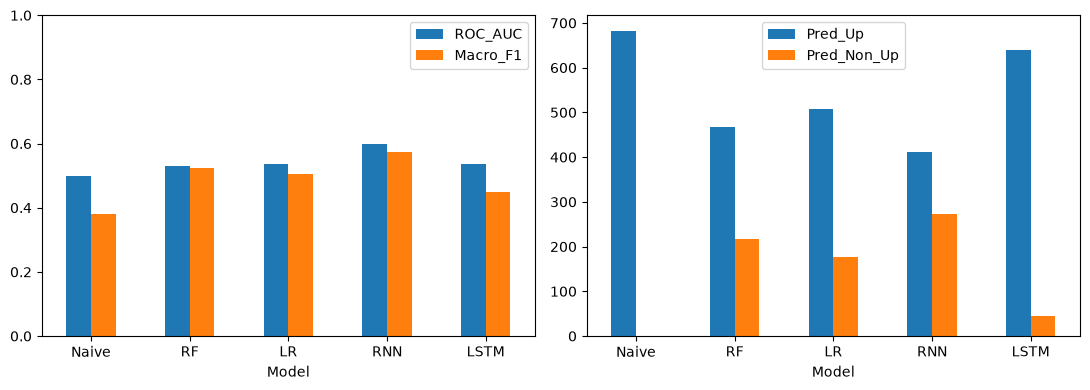

In [12]:
all_metrics=pd.concat([tabular,rnn,lstm],ignore_index=True)
test=all_metrics.loc[all_metrics.Split.eq('test')]
print('Kết quả Test:');display(test.round(5))
folder=ROOT/f'results/classification/h{HORIZON}/model_{VARIANT}'

comparison_path = ROOT/'results/classification/test_model_comparison.csv'
previous = pd.read_csv(comparison_path) if comparison_path.exists() else pd.DataFrame()
if not previous.empty:
    previous = previous.loc[~(previous.Horizon.eq(HORIZON) & previous.Variant.eq(VARIANT))]
pd.concat([previous,test],ignore_index=True).sort_values(
    ['Horizon','Variant','Model']).to_csv(comparison_path,index=False)
fig,axes=plt.subplots(1,2,figsize=(11,4))
test.set_index('Model')[['ROC_AUC','Macro_F1']].plot.bar(ax=axes[0],rot=0)
axes[0].set_ylim(0,1)
test.set_index('Model')[['Pred_Up','Pred_Non_Up']].plot.bar(ax=axes[1],rot=0)
fig.tight_layout();plt.show()


## Calibration trên Test

Calibration đối chiếu xác suất Up dự đoán với tần suất Up quan sát theo 10 khoảng xác suất. Đường chéo biểu thị xác suất khớp tần suất quan sát.

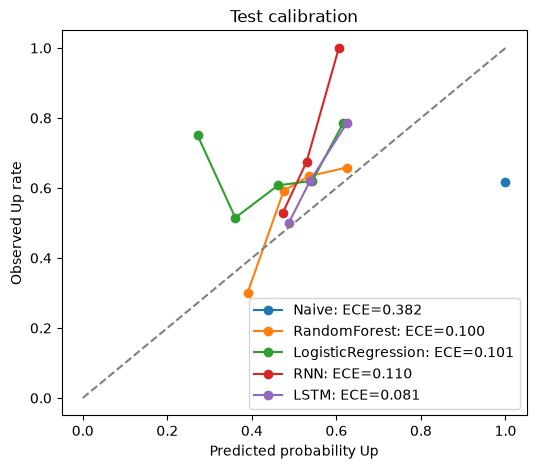

In [13]:
fig, ax = plt.subplots(figsize=(6,5))
for algorithm, label in MODEL_NAMES.items():
    prediction = pd.read_csv(folder/f'{label}_test_predictions.csv')
    bins, ece = calibration(prediction.Actual,prediction.Probability_Up)
    valid = bins.loc[bins.Count.gt(0)]
    ax.plot(valid.Mean_Probability_Up,valid.Observed_Up_Rate,marker='o',label=f'{label}: ECE={ece:.3f}')
ax.plot([0,1],[0,1],'--',color='gray')
ax.set(xlabel='Predicted probability Up',ylabel='Observed Up rate',title='Test calibration')
ax.legend(); plt.show()
